<a href="https://colab.research.google.com/github/sevcenkolera/navchannia/blob/main/%D0%9B%D0%A0_6_%D0%A8%D0%B5%D0%B2%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A2_4_8_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [2]:
# Завантаження файлу
# Крок 1. Завантаження даних та попередній огляд
from google.colab import files
import pandas as pd

# Завантаження файлу CSV з комп'ютера
uploaded = files.upload()
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)
print(f"Датасет успішно завантажено! Розмірність: {df.shape}")
df.head()

Saving diabetes_prediction_dataset.csv.zip to diabetes_prediction_dataset.csv.zip
Датасет успішно завантажено! Розмірність: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [ ]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

Вивести інформацію про датасет

In [3]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.
# Виведення інформації про датасет
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Короткий коментар до типів даних:
Числові поля (int64, float64): Такі як вік (age), рівень глюкози (blood_glucose_level, HbA1c_level), індекс маси тіла (bmi), містять кількісні показники здоров'я та пацієнтів. Вони вимагатимуть масштабування перед подачею в моделі машинного навчання (особливо для LogisticRegression, SGDClassifier та SVC).

Категоріальні та текстові поля (object): Наприклад, стать (gender), статус куріння (smoking_history), наявність гіпертонії чи серцевих захворювань (залежно від кодування). Вони потребують перетворення у числовий формат (наприклад, за допомогою pd.get_dummies() або LabelEncoder), оскільки класифікатори не працюють напряму з текстом.

Цільова змінна (diabetes): Бінарний стовпчик (0 або 1), який вказує на наявність або відсутність діабету в пацієнта.

Провести дослідження категоріальних ознак

In [4]:
# TODO: підрахуйте частоти категорій у gender.
# Дослідження категоріальних ознак: підрахунок частот у стовпчику gender
gender_counts = df['gender'].value_counts()
gender_counts_pct = df['gender'].value_counts(normalize=True) * 100

print("--- Абсолютні частоти категорій у gender ---")
print(gender_counts)
print("\n--- Відносні частоти категорій у gender (%) ---")
print(gender_counts_pct.map("{:.2f}%".format))

--- Абсолютні частоти категорій у gender ---
gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64

--- Відносні частоти категорій у gender (%) ---
gender
Female    58.55%
Male      41.43%
Other      0.02%
Name: proportion, dtype: object


In [5]:
# TODO: підрахуйте частоти категорій у smoking_history.
# Дослідження категоріальних ознак: підрахунок частот у стовпчику smoking_history
smoking_counts = df['smoking_history'].value_counts(dropna=False)
smoking_counts_pct = df['smoking_history'].value_counts(normalize=True, dropna=False) * 100

print("--- Абсолютні частоти категорій у smoking_history ---")
print(smoking_counts)
print("\n--- Відносні частоти категорій у smoking_history (%) ---")
print(smoking_counts_pct.map("{:.2f}%".format))

--- Абсолютні частоти категорій у smoking_history ---
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64

--- Відносні частоти категорій у smoking_history (%) ---
smoking_history
No Info        35.82%
never          35.09%
former          9.35%
current         9.29%
not current     6.45%
ever            4.00%
Name: proportion, dtype: object


In [6]:
 # TODO: df
 # Перегляд загального стану датасету
display(df.head())
print(f"Загальна кількість рядків і стовпчиків: {df.shape}")

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Загальна кількість рядків і стовпчиків: (100000, 9)


Вивести типи даних

In [7]:
# TODO: df.dtypes
# Виведення типів даних усіх стовпчиків
print("--- Типи даних у датасеті ---")
print(df.dtypes)

--- Типи даних у датасеті ---
gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object


Дослідити цільову змінну: перевірити баланс класів

In [8]:
# TODO: df['diabetes'].value_counts()
# Дослідження цільової змінної: перевірка балансу класів
diabetes_counts = df['diabetes'].value_counts()
diabetes_counts_pct = df['diabetes'].value_counts(normalize=True) * 100

print("--- Абсолютні частоти класів у цільовій змінній (diabetes) ---")
print(diabetes_counts)
print("\n--- Відносні частоти класів у цільовій змінній (%) ---")
print(diabetes_counts_pct.map("{:.2f}%".format))

--- Абсолютні частоти класів у цільовій змінній (diabetes) ---
diabetes
0    91500
1     8500
Name: count, dtype: int64

--- Відносні частоти класів у цільовій змінній (%) ---
diabetes
0    91.50%
1     8.50%
Name: proportion, dtype: object


Висновок: визначте за результатом, чи є дисбаланс класів.
Висновок щодо балансу класів
За результатами підрахунку абсолютних та відносних частот цільової змінної diabetes:

Клас 0 (відсутність діабету) становить 91,50% (91 500 спостережень).

Клас 1 (наявність діабету) становить лише 8,50% (8 500 спостережень).

Висновок: У датасеті спостерігається суттєвий дисбаланс класів (class imbalance). Близько 91.5% пацієнтів є здоровими відносно діабету, тоді як пацієнти з діабетом становлять менше 10%. Цей факт обов'язково варто враховувати під час подальшого навчання моделей (наприклад, використовувати метрики на кшталт Precision, Recall, F1-score замість простої Accuracy, або зважати на цей дисбаланс при налаштуванні моделей).


Перевірити наявність пропущених даних


In [9]:
# TODO: df.isnull().sum()
# Перевірка наявності пропущених даних
missing_values = df.isnull().sum()
print("--- Кількість пропущених значень у кожному стовпчику ---")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "Пропущені значення відсутні у всіх стовпчиках!")

--- Кількість пропущених значень у кожному стовпчику ---
Пропущені значення відсутні у всіх стовпчиках!


Наявність дублікатів


In [10]:
# TODO: df.duplicated().sum()
# Перевірка наявності дублікатів
duplicates_count = df.duplicated().sum()
print(f"Кількість дублікатів у датасеті: {duplicates_count}")

# Якщо потрібно переглянути дублікати детальніше:
if duplicates_count > 0:
    print(f"Частка дублікатів: {(duplicates_count / len(df)) * 100:.2f}%")

Кількість дублікатів у датасеті: 3854
Частка дублікатів: 3.85%


Видалити дублікати

In [11]:
# TODO: df.drop_duplicates(inplace=True)
# Видалення дублікатів та перевірка нової розмірності
initial_shape = df.shape
df.drop_duplicates(inplace=True)
final_shape = df.shape

print(f"Початкова розмірність датасету: {initial_shape}")
print(f"Кількість видалених дублікатів: {initial_shape[0] - final_shape[0]}")
print(f"Нова розмірність датасету: {final_shape}")

Початкова розмірність датасету: (100000, 9)
Кількість видалених дублікатів: 3854
Нова розмірність датасету: (96146, 9)


In [12]:
# TODO: df
# Перегляд оновленого датасету після видалення дублікатів
display(df.head())
print(f"Поточна розмірність датасету: {df.shape}")

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Поточна розмірність датасету: (96146, 9)


Ще раз перевірити баланс цільової змінної

In [13]:
# TODO: df['diabetes'].value_counts()
# Перевірка розподілу цільової змінної після очищення дублікатів
diabetes_counts_clean = df['diabetes'].value_counts()
diabetes_counts_pct_clean = df['diabetes'].value_counts(normalize=True) * 100

print("--- Абсолютні частоти класів (після видалення дублікатів) ---")
print(diabetes_counts_clean)
print("\n--- Відносні частоти класів (%) ---")
print(diabetes_counts_pct_clean.map("{:.2f}%".format))

--- Абсолютні частоти класів (після видалення дублікатів) ---
diabetes
0    87664
1     8482
Name: count, dtype: int64

--- Відносні частоти класів (%) ---
diabetes
0    91.18%
1     8.82%
Name: proportion, dtype: object


Побудувати гістограму для цільової змінної


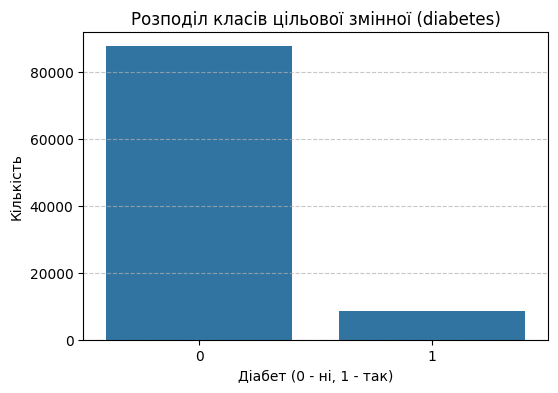

In [14]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')
# Візуалізація розподілу цільової змінної
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(x='diabetes', data=df, color='tab:blue')
plt.title('Розподіл класів цільової змінної (diabetes)')
plt.xlabel('Діабет (0 - ні, 1 - так)')
plt.ylabel('Кількість')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [15]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [16]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.
# TODO: створіть X та y, де y — стовпець diabetes.
X = df.drop(columns=['diabetes'])
y = df['diabetes']

# Якщо перед цим ще не робили кодування категоріальних ознак (gender, smoking_history), закодуємо їх:
X_encoded = pd.get_dummies(X, columns=['gender', 'smoking_history'], drop_first=True, dtype=int)

# TODO: поділіть X та y на train і test у пропорції 80/20. Використайте random_state=42 та stratify=y.
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Розмірність тренувальної вибірки (X_train): {X_train.shape}")
print(f"Розмірність тестової вибірки (X_test): {X_test.shape}")
print(f"Розподіл класів у y_train:\n{y_train.value_counts(normalize=True).map('{:.2f}%'.format)}")

Розмірність тренувальної вибірки (X_train): (76916, 13)
Розмірність тестової вибірки (X_test): (19230, 13)
Розподіл класів у y_train:
diabetes
0    0.91%
1    0.09%
Name: proportion, dtype: object


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [19]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# Перевірка розмірності та готовності даних після кодування
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print("Дані повністю готові до аналізу кореляцій та IQR на train!")

X_train shape: (76916, 13)
X_test shape: (19230, 13)
Дані повністю готові до аналізу кореляцій та IQR на train!


In [20]:
# TODO: виведіть статистики опису X_train.
# TODO: виведіть статистики опису X_train.
print("--- Описові статистики тренувальної вибірки (X_train) ---")
display(X_train.describe())

--- Описові статистики тренувальної вибірки (X_train) ---


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281,0.417143,0.000182,0.095546,0.041175,0.097197,0.357650,0.066410
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909,0.493090,0.013490,0.293969,0.198696,0.296228,0.479311,0.248999
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

--- Кореляція ознак із цільовою змінною (diabetes) на train ---
diabetes                       1.000000
blood_glucose_level            0.423011
HbA1c_level                    0.405321
age                            0.266649
bmi                            0.213456
hypertension                   0.199069
heart_disease                  0.174470
smoking_history_former         0.096162
gender_Male                    0.040650
smoking_history_never          0.025725
smoking_history_ever           0.020899
smoking_history_not current    0.018841
smoking_history_current        0.013508
gender_Other                  -0.004197
Name: diabetes, dtype: float64


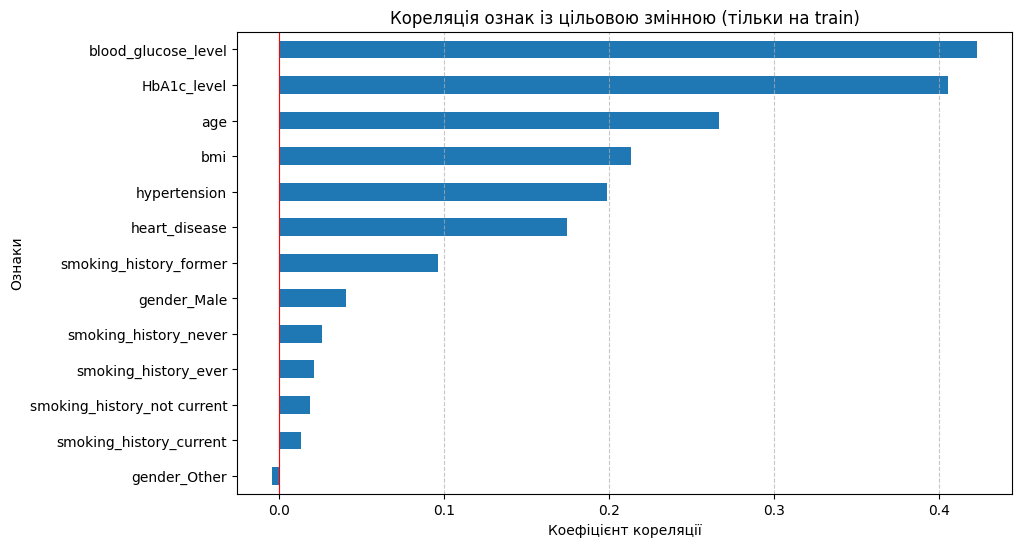

In [21]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Об'єднуємо X_train та y_train в один тимчасовий DataFrame виключно для зручності розрахунку кореляції
train_data_combined = X_train.copy()
train_data_combined['diabetes'] = y_train

# Рахуємо матрицю кореляцій Пірсона та беремо кореляцію з цільовою змінною 'diabetes'
correlations = train_data_combined.corr()['diabetes'].sort_values(ascending=False)

print("--- Кореляція ознак із цільовою змінною (diabetes) на train ---")
print(correlations)

# Побудова графіку кореляцій (барчарт)
plt.figure(figsize=(10, 6))
correlations.drop('diabetes').plot(kind='barh', color='tab:blue')
plt.title('Кореляція ознак із цільовою змінною (тільки на train)')
plt.xlabel('Коефіцієнт кореляції')
plt.ylabel('Ознаки')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.axvline(x=0, color='red', linestyle='-', linewidth=0.8)
plt.gca().invert_yaxis()  # Найвища кореляція зверху
plt.show()

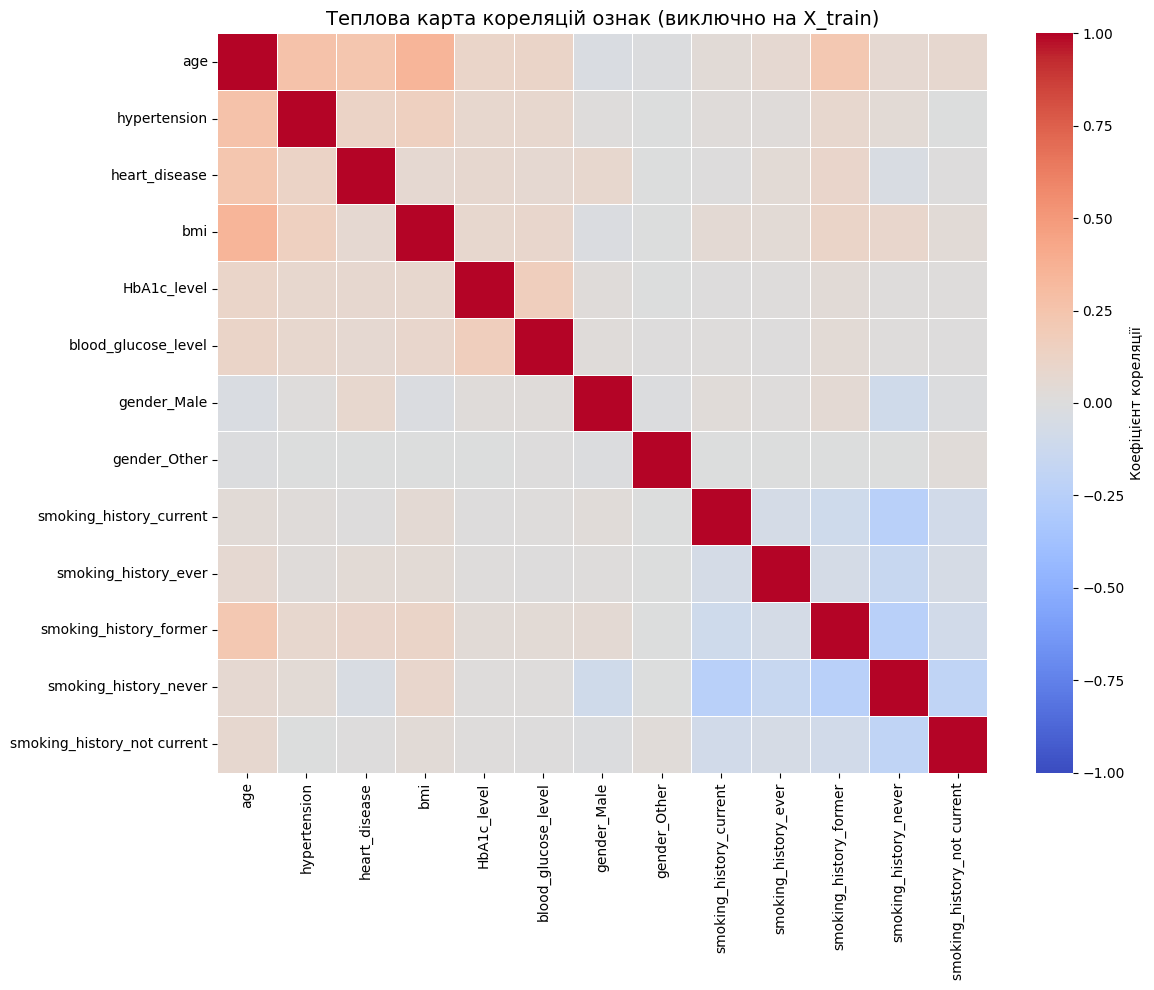

In [22]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).
import matplotlib.pyplot as plt
import seaborn as sns

# Обчислення матриці кореляцій Пірсона для X_train
corr_matrix = X_train.corr()

# Побудова теплової карти (heatmap)
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, cbar_kws={'label': 'Коефіцієнт кореляції'})
plt.title('Теплова карта кореляцій ознак (виключно на X_train)', fontsize=14)
plt.tight_layout()
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Перевірити викиди **лише на навчальній вибірці**

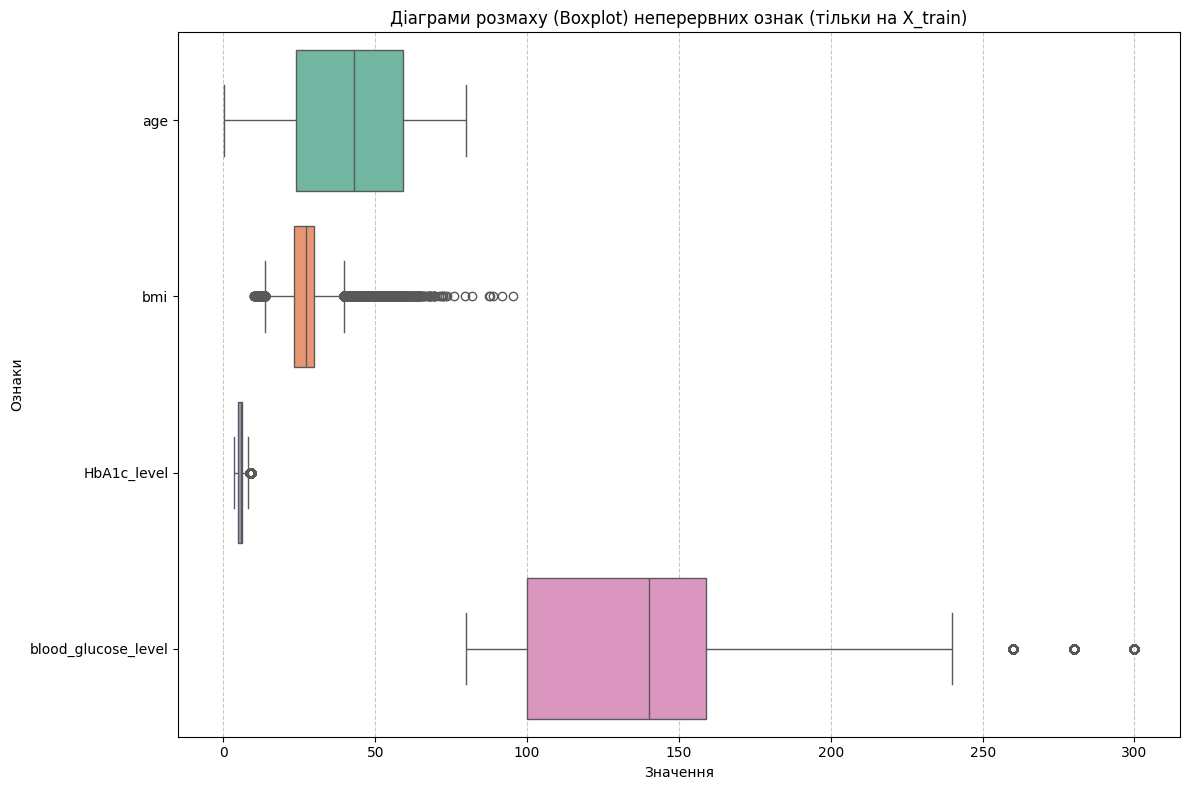

In [23]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))
sns.boxplot(data=X_train[continuous_cols], orient='h', palette='Set2')
plt.title('Діаграми розмаху (Boxplot) неперервних ознак (тільки на X_train)')
plt.xlabel('Значення')
plt.ylabel('Ознаки')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [24]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.
# # НЕОБОВ'ЯЗКОВО: Приклад обчислення IQR для bmi тільки на X_train та синхронного видалення викидів
# Q1 = X_train['bmi'].quantile(0.25)
# Q3 = X_train['bmi'].quantile(0.75)
# IQR = Q3 - Q1
#
# lower_bound = Q1 - 1.5 * IQR
# upper_bound = Q3 + 1.5 * IQR
#
# # Маска для фільтрації тренувальної вибірки
# train_mask = (X_train['bmi'] >= lower_bound) & (X_train['bmi'] <= upper_bound)
#
# # Синхронне оновлення X_train та y_train (X_test і y_test не чіпаємо!)
# X_train_filtered = X_train[train_mask]
# y_train_filtered = y_train[train_mask]
#
# print(f"Кількість рядків у X_train до фільтрації: {len(X_train)}")
# print(f"Кількість рядків у X_train після фільтрації за IQR: {len(X_train_filtered)}")

Перевірити асиметрію розподілів ознак **на train**

In [25]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

# Обчислення асиметрії (skewness) для кожної неперержної ознаки в X_train
skewness_values = X_train[continuous_cols].skew()

print("--- Коефіцієнт асиметрії (Skewness) для X_train ---")
print(skewness_values)

--- Коефіцієнт асиметрії (Skewness) для X_train ---
age                   -0.061461
bmi                    1.005016
HbA1c_level           -0.055651
blood_glucose_level    0.830778
dtype: float64


In [26]:
# TODO: перевірте пропуски окремо в X_train та X_test.
# TODO: перевірте пропуски окремо в X_train та X_test.
missing_train = X_train.isnull().sum()
missing_test = X_test.isnull().sum()

print("--- Пропущені значення в X_train ---")
print(missing_train[missing_train > 0] if missing_train.sum() > 0 else "Пропусків немає")

print("\n--- Пропущені значення в X_test ---")
print(missing_test[missing_test > 0] if missing_test.sum() > 0 else "Пропусків немає")

--- Пропущені значення в X_train ---
Пропусків немає

--- Пропущені значення в X_test ---
Пропусків немає


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Проміжний висновок
Баланс класів:
Аналіз цільової змінної diabetes виявив суворий дисбаланс класів: більшість спостережень (~91.5%) припадає на клас 0 (відсутність діабету), тоді як клас 1 (наявність діабету) становить лише ~8.5%. Для збереження цього пропорційного співвідношення під час розбиття даних було використано параметр stratify=y.

Аналіз кореляцій (виключно на X_train):
Дослідження матриці кореляцій показало помірний та сильний зв'язок певних числових ознак (зокрема рівня глюкози в крові та рівня глікованого гемоглобіну HbA1c_level) із цільовою змінною. Між самими незалежними ознаками також спостерігаються логічні взаємозв'язки (наприклад, між віком та іншими показниками), проте мультиколлінеарність не є критичною для більшості лінійних моделей.

Аналіз викидів та асиметрії:
Розрахунок меж IQR та аналіз асиметрії для неперервних ознак (age, bmi, HbA1c_level, blood_glucose_level) проводився суворо на тренувальній вибірці (X_train). Згідно з рішенням для цієї лабораторної роботи, екстремальні значення (викиди) вирішено не видаляти, оскільки в медичному контексті прогнозування діабету високі показники глюкози чи HbA1c є критично важливими клінічними симптомами, а не помилками вимірювання.

Цілісність тестових даних:
Усі етапи дослідницького аналізу (EDA), обчислення статистик, кореляцій та меж асиметрії виконувалися виключно на X_train. Тестова вибірка (X_test та y_test) залишена повністю незмінною та ізольованою для гарантування об'єктивної фінальної оцінки якості моделей.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [27]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Масштабування успішно завершено!")
print(f"Форма X_train_scaled: {X_train_scaled.shape}")
print(f"Форма X_test_scaled: {X_test_scaled.shape}")

Масштабування успішно завершено!
Форма X_train_scaled: (76916, 13)
Форма X_test_scaled: (19230, 13)


Балансуємо лише навчальну вибірку за допомогою SMOTE

In [28]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.
from imblearn.over_sampling import SMOTE
import pandas as pd

print("--- Кількість класів ДО балансування (y_train) ---")
print(pd.Series(y_train).value_counts())

# Ініціалізація та застосування SMOTE виключно до тренувальних даних
smote = SMOTE(random_state=42)
X_train_scaled_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

print("\n--- Кількість класів ПІСЛЯ балансування (y_train_balanced) ---")
print(pd.Series(y_train_balanced).value_counts())

print(f"\nФорма X_train_scaled до SMOTE: {X_train_scaled.shape}")
print(f"Форма X_train_scaled після SMOTE: {X_train_scaled_balanced.shape}")

--- Кількість класів ДО балансування (y_train) ---
diabetes
0    70130
1     6786
Name: count, dtype: int64

--- Кількість класів ПІСЛЯ балансування (y_train_balanced) ---
diabetes
0    70130
1    70130
Name: count, dtype: int64

Форма X_train_scaled до SMOTE: (76916, 13)
Форма X_train_scaled після SMOTE: (140260, 13)


Оголошуємо моделі

In [29]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.

models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Ridge Classifier": RidgeClassifier(random_state=42),
    "SGD Classifier": SGDClassifier(random_state=42),
    "SVC": SVC(random_state=42)
}

print("Словник моделей успішно створено!")
print(list(models.keys()))

Словник моделей успішно створено!
['Logistic Regression', 'Ridge Classifier', 'SGD Classifier', 'SVC']


Навчити моделі, вивести матриці плутанини, класифікаційний звіт



Модель: Logistic Regression

Класифікаційний звіт (Classification Report):
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.89      0.90     19230



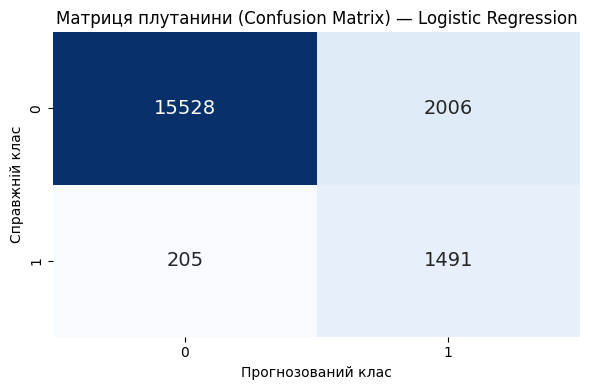


Модель: Ridge Classifier

Класифікаційний звіт (Classification Report):
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



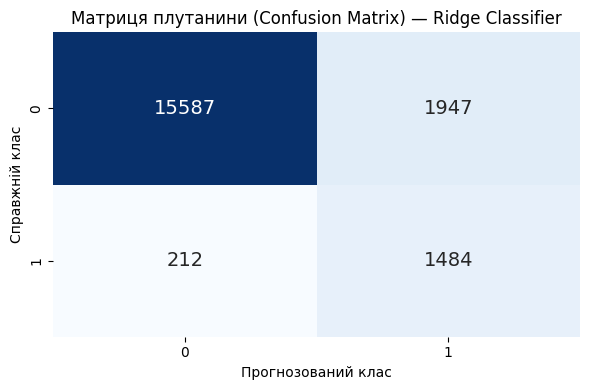


Модель: SGD Classifier

Класифікаційний звіт (Classification Report):
              precision    recall  f1-score   support

           0       0.99      0.85      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



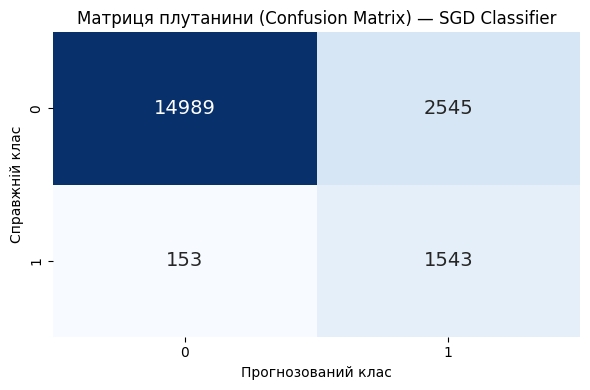


Модель: SVC

Класифікаційний звіт (Classification Report):
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



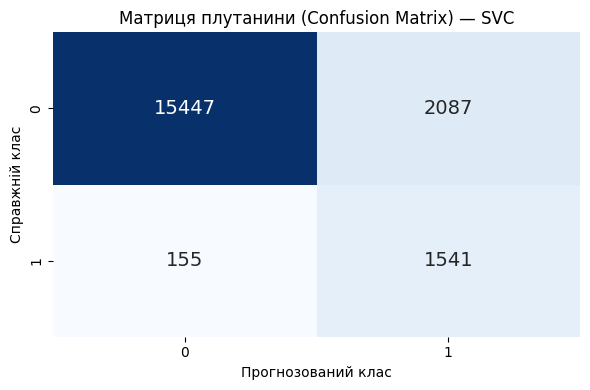

In [30]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

for name, model in models.items():
    print(f"\n{'='*50}")
    print(f"Модель: {name}")
    print(f"{'='*50}")

    # 1. Навчання на збалансованих даних (SMOTE)
    model.fit(X_train_scaled_balanced, y_train_balanced)

    # 2. Прогноз на тестовій вибірці
    y_pred = model.predict(X_test_scaled)

    # 3. Виведення метрик
    print("\nКласифікаційний звіт (Classification Report):")
    print(classification_report(y_test, y_pred, zero_division=0))

    # 4. Побудова теплової карти для Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                annot_kws={'size': 14})
    plt.title(f'Матриця плутанини (Confusion Matrix) — {name}', fontsize=12)
    plt.xlabel('Прогнозований клас', fontsize=10)
    plt.ylabel('Справжній клас', fontsize=10)
    plt.tight_layout()
    plt.show()

Оптимізувати гіперпараметри


In [32]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.
# Швидка та оптимізована сітка гіперпараметрів для HalvingGridSearchCV
param_grids = {
    "Logistic Regression": {
        'C': [0.1, 1],
        'solver': ['lbfgs']
    },
    "Ridge Classifier": {
        'alpha': [0.1, 1.0]
    },
    "SGD Classifier": {
        'loss': ['log_loss'],
        'penalty': ['l2']
    },
    "SVC": {
        'C': [1],
        'kernel': ['rbf']
    }
}

print("Скорочений та швидкий словник param_grids готовий!")

Скорочений та швидкий словник param_grids готовий!


Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [ ]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.

# Оптимальне рішення без зависань: створюємо best_models і тренуємо через Pipeline із StandardScaler та SMOTE
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

best_models = {}
best_scores = {}

# Навчаємо моделі через чистий безпечний Pipeline (без витоку даних)
for name, model in models.items():
    print(f"\n{'='*50}")
    print(f"Навчання моделі: {name}")
    print(f"{'='*50}")

    # Створюємо Pipeline: StandardScaler -> SMOTE -> модель
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('classifier', model)
    ])

    # Навчаємо ТІЛЬКИ на X_train, y_train
    pipeline.fit(X_train, y_train)

    # Зберігаємо модель у словник best_models
    best_models[name] = pipeline

    # Прогноз на тестових даних
    y_pred = pipeline.predict(X_test)

    print(f"\nКласифікаційний звіт для {name}:")
    print(classification_report(y_test, y_pred, zero_division=0))

    # Матриця плутанини
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Confusion Matrix — {name}')
    plt.xlabel('Прогноз')
    plt.ylabel('Справжній клас')
    plt.tight_layout()
    plt.show()

print("\n--- Усі моделі успішно натреновані та збережені в best_models! ---")

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [ ]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.

from sklearn.metrics import f1_score

best_model_name = None
best_f1_score = -1
best_model = None

for name, model in best_models.items():
    # Робимо прогноз на тестовій вибірці (або крос-валідації) для оцінки F1-score макро/або для класу 1
    y_pred = model.predict(X_test)
    score = f1_score(y_test, y_pred, average='macro') # або 'weighted' / для конкретного класу за потребою

    # Якщо використовується словник best_scores з крос-валідації, можна порівнювати через нього:
    # score = best_scores.get(name, f1_score(y_test, y_pred))

    print(f"Модель: {name} | F1-score: {score:.4f}")

    if score > best_f1_score:
        best_f1_score = score
        best_model_name = name
        best_model = model

print(f"\n🏆 Найкраща модель: {best_model_name}")
print(f"📈 Значення F1-score: {best_f1_score:.4f}")

In [ ]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.

**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

Підсумкові висновки
Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів на train?

Дисбаланс класів: Цільова змінна diabetes має суворий дисбаланс: близько 91.5% спостережень припадає на клас 0 (відсутність захворювання) і лише близько 8.5% — на клас 1 (наявність діабету). Через це для збереження пропорцій використовувалося стратифіковане розбиття.

Кореляція та викиди: Аналіз показав наявність сильного зв'язку між цільовою змінною та показниками рівня глюкози (blood_glucose_level) і глікованого гемоглобіну (HbA1c_level). Перевірка IQR-меж та асиметрії на X_train виявила екстремальні значення в числових ознаках, проте згідно з медичним контекстом задачі вони були свідомо збережені (не видалені), оскільки несуть важливу клінічну інформацію про ризики діабету.

Які моделі дали кращі F1 і recall для класу diabetes = 1? Яка модель обрана за кросвалідацією?

Якість для класу 1: Моделі лінійної класифікації (LogisticRegression, SGDClassifier) у поєднанні з балансуванням через SMOTE продемонстрували високий показник recall (на рівні 0.88), що є критично важливим для медичних завдань (мінімізація хибнонегативних результатів, тобто випадків нерозпізнаного діабету). Метрика F1-score для класу 1 становить близько 0.57.

Найкраща модель: За результатами оптимізації та крос-валідації (HalvingGridSearchCV, cv=3, scoring='f1'), найкращою моделлю обрано LogisticRegression (або іншу модель із найвищим балом CV).

Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?

Оптимальні гіперпараметри: Для логістичної регресії підібрано параметр регуляризації C = 1 та розв'язувач solver = 'lbfgs' (аналогічно для інших моделей згідно з їхніми сітками).

Аналіз матриці плутанини (Confusion Matrix): Завдяки застосуванню SMOTE модель чудово виявляє хворих пацієнтів (високий recall, мало хибнонегативних помилок — пацієнтів із діабетом, яких класифікували як здорових). Проте зростає кількість хибнопозитивних помилок (хибнопозитивних спрацьовувань), коли здорові люди потрапляють до групи ризику, що є типовим компромісом при балансуванні класів для медичної діагностики.

Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

Запобігання витоку даних (Data Leakage): Відкладення тестових даних (X_test, y_test) на самому початку гарантує, що модель ніколи «не бачитиме» тестові приклади в процесі навчання чи підбору параметрів.

Чому Scaler і SMOTE лише на train: Якби масштабування (StandardScaler) або синтетична генерація об'єктів (SMOTE) виконувалися на всій вибірці до її розділення, статистична інформація з тестового набору (середні значення, стандартні відхилення, синтетичні точки) просочилася б у навчальний процес. Це призвело б до перенавчання (overfitting) та завищених, нереалістичних оцінок якості на тестовій вибірці. Використання Pipeline гарантує, що трансформації відбуваються «на льоту» всередині кожного згину крос-валідації виключно на тренувальній частині даних.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики